Paquetes necesarios

In [1]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia implicaría en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y milímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



El valor total es: 3.88 euros


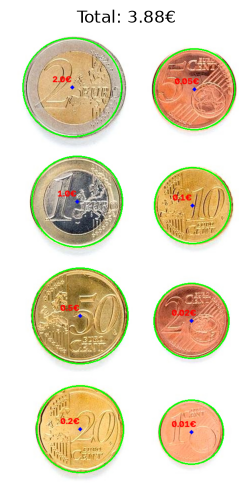

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


DIAMETROS_EURO_MM = {
    2.00: 25.75,
    0.50: 24.25,
    1.00: 23.25,
    0.20: 22.25,
    0.05: 21.25,
    0.10: 19.75,
    0.02: 18.75,
    0.01: 16.25
}

img_monedas = cv2.imread('Monedas.jpg')     # si se pone Monedas_mias.jpg, se prueba con otra imagen, pero los datos que proporciona no son correctos.)
img_rgb = cv2.cvtColor(img_monedas, cv2.COLOR_BGR2RGB)
img_gris = cv2.cvtColor(img_monedas, cv2.COLOR_BGR2GRAY)

img_gris = cv2.medianBlur(img_gris, 5)

circulos = cv2.HoughCircles(img_gris, cv2.HOUGH_GRADIENT, dp=1, minDist=100, param1=100, param2=40, minRadius=30, maxRadius=130)

circulos = np.uint16(np.around(circulos))

resultado = img_rgb.copy()

for c in circulos[0, :]:
    x = int(c[0])
    y = int(c[1])
    r = int(c[2])
    cv2.circle(resultado, (x, y), r, (0, 255, 0), 2)
    cv2.circle(resultado, (x, y), 2, (0, 0, 255), 3)

ventana = 'monedas detectadas: haz clic en la moneda de 1 euros'



punto_clic = [None, None] 

def clic(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        punto_clic[0] = x
        punto_clic[1] = y

cv2.namedWindow(ventana,cv2.WINDOW_NORMAL)

cv2.setMouseCallback(ventana, clic)
cv2.imshow(ventana, resultado)



while punto_clic[0] is None or punto_clic[1] is None:
    cv2.waitKey(1)

cv2.destroyAllWindows()

radio_ref = 0

for c in circulos[0, :]:
    x = int(c[0])
    y = int(c[1])
    r = int(c[2])
    distancia = np.sqrt((x - punto_clic[0]) ** 2 + (y - punto_clic[1]) ** 2)


    if distancia < r:
        radio_ref = r
        break

escala = (2 * radio_ref) / DIAMETROS_EURO_MM[1.00]

total = 0

for c in circulos[0, :]:
    x = int(c[0])
    y = int(c[1])
    r = int(c[2])
    diametro_mm = (2 * r) / escala

    diferencia_minima = float('inf')
    valor = 0

    for moneda in DIAMETROS_EURO_MM:
        
        diferencia = abs(diametro_mm - DIAMETROS_EURO_MM[moneda])
        if diferencia < diferencia_minima:
            diferencia_minima = diferencia
            valor = moneda
        
    
    total += valor

    cv2.circle(resultado, (x, y), r, (0, 255, 0), 2)
    cv2.putText(resultado, f"{valor}€", (x - 40, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

img = cv2.cvtColor(resultado, cv2.COLOR_RGB2BGR)

cv2.namedWindow('Resultado', cv2.WINDOW_NORMAL)
cv2.resizeWindow('Resultado', 1200, 900)
cv2.imshow('Resultado', img)
print(f"El valor total es: {total:.2f} euros")

cv2.waitKey(0)
cv2.destroyAllWindows()

plt.figure(figsize=(8, 6))
plt.imshow(resultado)
plt.title(f'Total: {total:.2f}€')
plt.axis('off')
plt.show()



In [84]:
DIAMETROS_EURO_MM = {
    2.00: 25.75,
    0.50: 24.25,
    1.00: 23.25,
    0.20: 22.25,
    0.05: 21.25,
    0.10: 19.75,
    0.02: 18.75,
    0.01: 16.25
}



vid = cv2.VideoCapture(1)


escala = 3.5


while(True):      
    # fotograma a fotograma
    ret, frame = vid.read()

    if ret:
        # Aplica efecto espejo sobre la entrada
        framem=cv2.flip(frame, 1)
        gris = cv2.cvtColor(framem, cv2.COLOR_BGR2GRAY)
        gris = cv2.medianBlur(gris, 5)

        circulos = cv2.HoughCircles(gris, cv2.HOUGH_GRADIENT, dp=1.2, minDist=100, param1=100, param2=30, minRadius=10, maxRadius=80)


        resultado = framem.copy()
        total = 0

        if circulos is not None:
            circulos = np.uint16(np.around(circulos))
            for c in circulos[0, :]:
                x = int(c[0])
                y = int(c[1])
                r = int(c[2])
                diametro_mm = (2 * r) / escala
                diferencia_minima = float('inf')
                valor = 0
                for moneda in DIAMETROS_EURO_MM:
                    diferencia = abs(diametro_mm - DIAMETROS_EURO_MM[moneda])
                    if diferencia < diferencia_minima:
                        diferencia_minima = diferencia
                        valor = moneda
                if diferencia_minima < 2.5:
                    total += valor
                    cv2.circle(resultado, (x, y), r, (0, 255, 0), 2)
                    cv2.putText(resultado, f"{valor}€", (x - 40, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
                else:
                    cv2.circle(resultado, (x, y), r, (0, 0, 255), 2)
                    cv2.putText(resultado, "Desconocida", (x - 40, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

            cv2.putText(resultado, f"Total: {total:.2f}€", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
        cv2.imshow('Detector de monedas', resultado)

        if cv2.waitKey(20) == 27:
            break

        
vid.release()
cv2.destroyAllWindows()


La segunda tarea plantea la clasificación de microplásticos en una imagen real. Dado que el mundo real es muy variado, las imágenes no siempre se capturan con unas condiciones de iluminación tan buenas o controladas. Ejemplo con aplicación de variantes de umbralizados ofrecidas por OpenCV sobre una imagen de muestras de microplásticos.

El objetivo de la siguiente tarea, descrita más abajo, es desarrollar tu propio clasificador basado únicamente en heurísticas basadas en características geométricas y/o de apariencia, a partir de las imágenes completas de las partículas de cada tipo, debiendo mostrar la bondad del clasificador haciendo uso de métricas para ello sobre las anotaciones de la imagen de test *MPs_test.png*. La siguiente celda obtiene varias métricas para un conjunto de datos imaginario (y con etiquetas aleatorias). Si bien las trataremos con más detalle en teoría, muestro un repertorio de ellas, dando más peso a la matriz de confusión. La ejecución de la celda requiere instalar el paquete scikit-learn.

¿Qué es una matriz de confusión?
Se utiliza para mostrar el comportamiento de un clasificador para las distintas clases conocidas, se relacionan las etiquetas de las muestras anotadas frente a las predichas por el clasificador. Se busca una matriz diagonal, pero la perfección es infrecuente.



TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [ ]:
import cv2, csv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

def contornos(img):
    gris = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5,5), 0)
    _, th = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]

def caracteristicas(img, c):
    area = cv2.contourArea(c)
    x, y, w, h = cv2.boundingRect(c)
    mascara = np.zeros(img.shape[:2], np.uint8)
    cv2.drawContours(mascara, [c], -1, 255, -1)
    perimetro = cv2.arcLength(c, True)

    return [
    np.log1p(area),
    max(w/h, h/w),
    area/(w*h),
    4*np.pi*area/(perimetro**2 + 1e-6)
]

X, y = [], []
archivos = [
    ("fragment-03-olympus-10-01-2020.JPG", "FRA"),
    ("pellet-03-olympus-10-01-2020.JPG", "PEL"),
    ("tar-03-olympus-10-01-2020.JPG", "TAR")
]

for archivo, clase in archivos:
    img = cv2.imread(archivo)
    for c in contornos(img):
        if cv2.contourArea(c) > 20:
            X.append(caracteristicas(img, c))
            y.append(clase)

modelo = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=3, class_weight="balanced")
)
modelo.fit(X, y)

print("Partículas de entrenamiento:", len(y))
for clase in ["FRA", "PEL", "TAR"]:
    print(clase, y.count(clase))

Partículas de entrenamiento: 577
FRA 250
PEL 270
TAR 57


Exactitud: 0.383
Predicciones: {'FRA': 36, 'PEL': 41, 'TAR': 43}


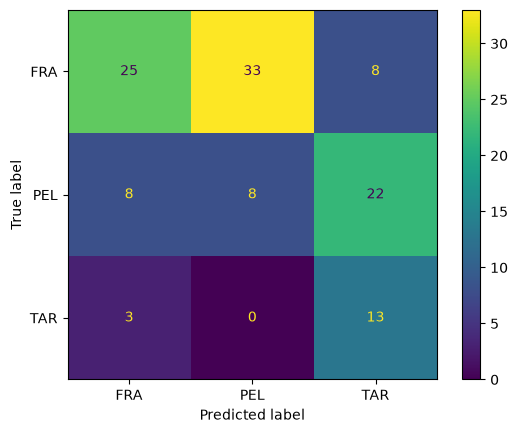

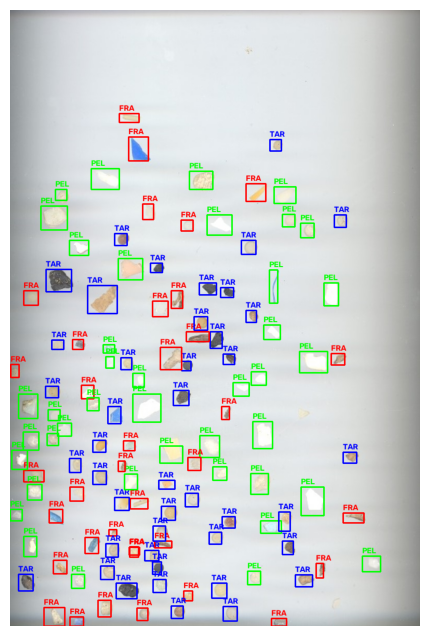

In [81]:
img = cv2.imread("MPs_test.jpg")
vista = img.copy()
verdaderas, predichas = [], []
colores = {"FRA": (0,0,255), "PEL": (0,255,0), "TAR": (255,0,0)}

with open("MPs_test_bbs.csv", newline="") as f:
    for fila in csv.DictReader(f):
        x1, y1, x2, y2 = [
            int(float(fila[k])) for k in ["x_min", "y_min", "x_max", "y_max"]
        ]
        recorte = img[y1:y2+1, x1:x2+1]
        if recorte.size == 0:
            continue

        candidatos = [c for c in contornos(recorte)
                      if cv2.contourArea(c) > 5]

        if candidatos:
            c = max(candidatos, key=cv2.contourArea)
        else:
            h, w = recorte.shape[:2]
            c = np.array([[[0,0]], [[w-1,0]],
                          [[w-1,h-1]], [[0,h-1]]], dtype=np.int32)

        pred = modelo.predict([caracteristicas(recorte, c)])[0]
        real = fila["label"]
        verdaderas.append(real)
        predichas.append(pred)

        cv2.rectangle(vista, (x1,y1), (x2,y2), colores[pred], 2)
        cv2.putText(vista, pred, (x1,y1-5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, colores[pred], 2)

clases = ["FRA", "PEL", "TAR"]
print("Exactitud:", round(accuracy_score(verdaderas, predichas), 3))
print("Predicciones:", {c: predichas.count(c) for c in clases})

ConfusionMatrixDisplay(
    confusion_matrix(verdaderas, predichas, labels=clases),
    display_labels=clases
).plot()
plt.show()

plt.figure(figsize=(14,8))
plt.imshow(cv2.cvtColor(vista, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()